# Análisis exploratorio — vivienda en venta en Andalucía

Conjunto de datos: `data/procesado/fotocasa_andalucia_limpio.csv`, generado por `src/limpieza.py`
(anuncios de Fotocasa con detalle validado, enriquecidos con INE y MIVAU).

Objetivos del análisis:

1. Caracterizar la variable objetivo (precio de oferta) y decidir su transformación.
2. Describir las diferencias territoriales y entre tipos de vivienda.
3. Identificar las variables con mayor relación con el precio.
4. Revisar los valores ausentes y extraer decisiones para el preprocesado y el modelado.

Las figuras se guardan en `doc/figuras/eda/` para la memoria.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from scipy import stats

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATOS = RAIZ / "data" / "procesado" / "fotocasa_andalucia_limpio.csv"
FIGURAS = RAIZ / "doc" / "figuras" / "eda"
FIGURAS.mkdir(parents=True, exist_ok=True)

# Paleta (validada para daltonismo): azul = pisos y otros, naranja = casas.
AZUL, NARANJA = "#2a78d6", "#eb6834"
TINTA, TINTA_2, REJILLA = "#0b0b0b", "#52514e", "#e4e3df"
SECUENCIAL = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": REJILLA, "axes.labelcolor": TINTA_2, "axes.titlecolor": TINTA,
    "xtick.color": TINTA_2, "ytick.color": TINTA_2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": REJILLA, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "legend.frameon": False,
})
miles = mticker.FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", "."))

def guardar(fig, nombre):
    fig.savefig(FIGURAS / f"{nombre}.png")
    plt.show()

df = pd.read_csv(DATOS, encoding="utf-8-sig", low_memory=False)
df["grupo"] = np.where(df["tipo_vivienda"] == "casa", "Casas", "Pisos y otros")
GRUPOS = {"Pisos y otros": AZUL, "Casas": NARANJA}
print(f"{len(df):,} viviendas × {df.shape[1]} columnas")

6,763 viviendas × 54 columnas


## 1. Visión general

In [2]:
resumen = pd.DataFrame({
    "viviendas": df.groupby("provincia").size(),
    "municipios": df.groupby("provincia")["cod_ine"].nunique(),
    "en capital (%)": (df.groupby("provincia")["es_capital"].mean() * 100).round(1),
    "precio mediano (€)": df.groupby("provincia")["precio_eur"].median(),
    "€/m² mediano": df.groupby("provincia")["precio_m2"].median().round(0),
}).sort_values("viviendas", ascending=False)
resumen.loc["Andalucía"] = [len(df), df["cod_ine"].nunique(), round(df["es_capital"].mean() * 100, 1),
                            df["precio_eur"].median(), round(df["precio_m2"].median())]
resumen.astype({"viviendas": int, "municipios": int, "precio mediano (€)": int, "€/m² mediano": int})

,viviendas,municipios,en capital (%),precio mediano (€),€/m² mediano
provincia,,,,,
Málaga,1641,20,11.4,425000,3676
Cádiz,1204,18,15.6,268000,2454
Jaén,819,21,29.3,130000,976
Córdoba,730,21,25.6,145000,1098
Almería,633,18,56.6,176100,1687
Granada,623,21,23.0,250000,2011
Sevilla,580,19,30.5,230000,1852
Huelva,533,18,26.6,190000,1797
Andalucía,6763,156,24.0,246000,2057


In [3]:
df["tipo_vivienda"].value_counts().to_frame("viviendas").assign(
    **{"%": lambda t: (t["viviendas"] / t["viviendas"].sum() * 100).round(1)})

,viviendas,%
tipo_vivienda,,
piso,2828,41.8
casa,2716,40.2
apartamento,481,7.1
ático,302,4.5
planta baja,166,2.5
dúplex,151,2.2
estudio,79,1.2
sin especificar,40,0.6


## 2. Variable objetivo: precio de oferta

El precio presenta una fuerte asimetría a la derecha. Se compara con su logaritmo para decidir
la variable que se modelará.

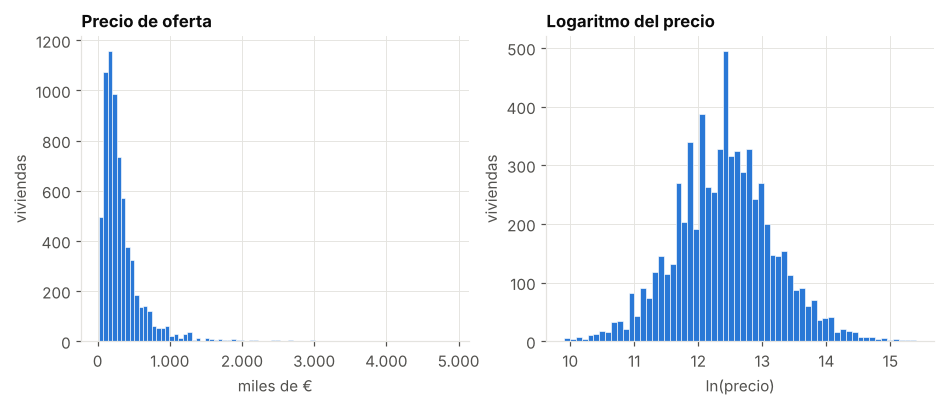

,asimetría,curtosis
precio,4.41,33.03
ln(precio),0.10,0.41


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].hist(df["precio_eur"] / 1000, bins=80, color=AZUL, edgecolor="white", linewidth=0.4)
ax[0].set(title="Precio de oferta", xlabel="miles de €", ylabel="viviendas")
ax[0].xaxis.set_major_formatter(miles)
ax[1].hist(df["log_precio"], bins=60, color=AZUL, edgecolor="white", linewidth=0.4)
ax[1].set(title="Logaritmo del precio", xlabel="ln(precio)", ylabel="viviendas")
guardar(fig, "01_distribucion_precio")

pd.DataFrame({
    "asimetría": [stats.skew(df["precio_eur"]), stats.skew(df["log_precio"])],
    "curtosis": [stats.kurtosis(df["precio_eur"]), stats.kurtosis(df["log_precio"])],
}, index=["precio", "ln(precio)"]).round(2)

**Lectura.** La transformación logarítmica corrige casi toda la asimetría. Se modelará `log_precio`
y las predicciones se devolverán a euros con la exponencial; así el error relativo pesa igual en
viviendas baratas y caras, y las métricas en euros (MAE, RMSE) se calcularán sobre la escala original.

## 3. Territorio

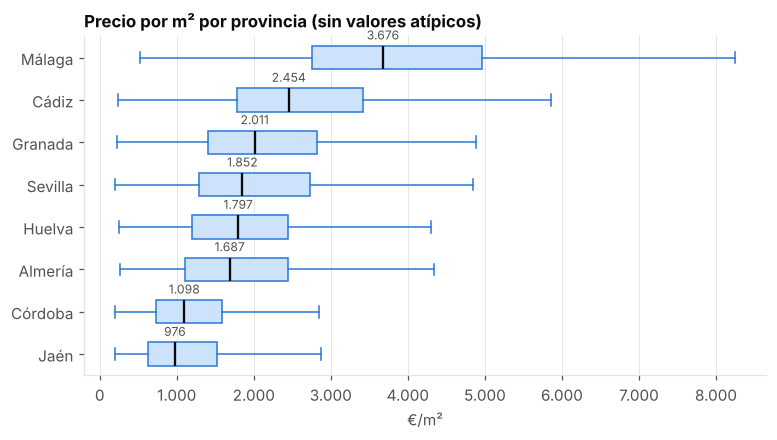

In [5]:
orden = df.groupby("provincia")["precio_m2"].median().sort_values().index
fig, ax = plt.subplots(figsize=(8, 4))
datos = [df.loc[df["provincia"] == p, "precio_m2"] for p in orden]
bp = ax.boxplot(datos, orientation="horizontal", tick_labels=orden, showfliers=False, widths=0.55, patch_artist=True,
                medianprops=dict(color=TINTA, linewidth=1.5),
                boxprops=dict(facecolor="#cde2fb", edgecolor=AZUL), whiskerprops=dict(color=AZUL),
                capprops=dict(color=AZUL))
for i, p in enumerate(orden, 1):
    m = df.loc[df["provincia"] == p, "precio_m2"].median()
    ax.text(m, i + 0.36, f"{m:,.0f}".replace(",", "."), ha="center", va="bottom", fontsize=8, color=TINTA_2)
ax.set(title="Precio por m² por provincia (sin valores atípicos)", xlabel="€/m²")
ax.xaxis.set_major_formatter(miles)
ax.grid(axis="y", visible=False)
guardar(fig, "02_precio_m2_provincia")

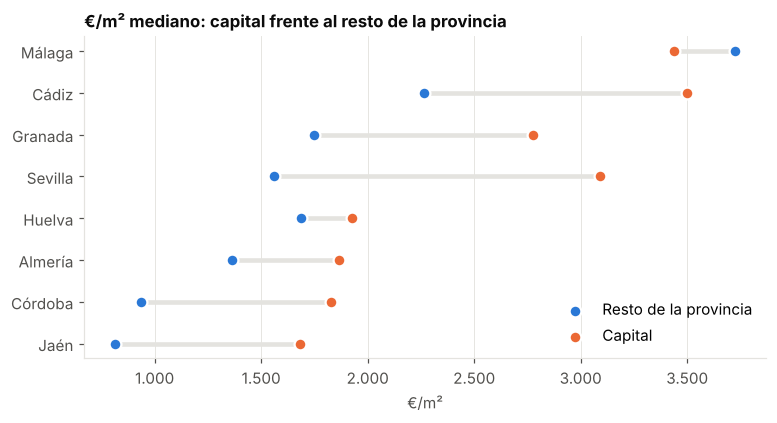

es_capital,resto,capital,capital / resto
provincia,,,
Jaén,814.0,1680.0,2.06
Córdoba,938.0,1827.0,1.95
Almería,1364.0,1864.0,1.37
Huelva,1688.0,1925.0,1.14
Sevilla,1561.0,3088.0,1.98
Granada,1749.0,2774.0,1.59
Cádiz,2264.0,3500.0,1.55
Málaga,3725.0,3438.0,0.92


In [6]:
cap = (df.groupby(["provincia", "es_capital"])["precio_m2"].median().unstack()
         .rename(columns={True: "capital", False: "resto"}).loc[orden])
fig, ax = plt.subplots(figsize=(8, 3.8))
y = np.arange(len(cap))
ax.hlines(y, cap.min(axis=1), cap.max(axis=1), color=REJILLA, linewidth=3, zorder=1)
ax.scatter(cap["resto"], y, s=60, color=AZUL, edgecolor="white", linewidth=1.5, zorder=2, label="Resto de la provincia")
ax.scatter(cap["capital"], y, s=60, color=NARANJA, edgecolor="white", linewidth=1.5, zorder=2, label="Capital")
ax.set_yticks(y, cap.index); ax.grid(axis="y", visible=False)
ax.set(title="€/m² mediano: capital frente al resto de la provincia", xlabel="€/m²")
ax.xaxis.set_major_formatter(miles)
ax.legend(loc="lower right")
guardar(fig, "03_capital_vs_resto")
cap.round(0).assign(**{"capital / resto": (cap["capital"] / cap["resto"]).round(2)})

**Lectura.** La provincia por sí sola no explica el precio: dentro de cada una hay mucha dispersión.
En siete de las ocho provincias la capital es más cara que el resto, con diferencias que llegan a
duplicar el €/m² (Jaén, Córdoba, Sevilla); la excepción es Málaga, donde los municipios de la Costa
del Sol superan a la capital. Esto justifica incluir variables a nivel municipal y la ubicación.

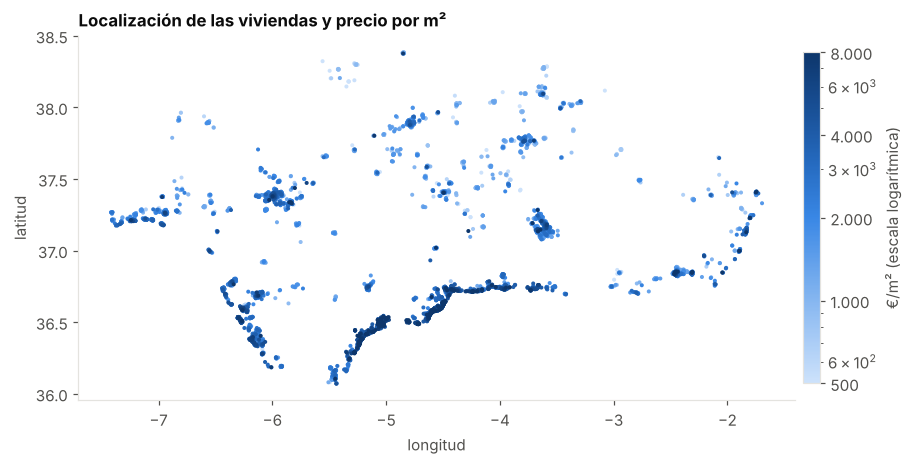

Viviendas con coordenadas válidas: 6,754 de 6,763


In [7]:
geo = df.dropna(subset=["latitud", "longitud"])
geo = geo[geo["latitud"].between(35.9, 38.8) & geo["longitud"].between(-7.6, -1.6)]
fig, ax = plt.subplots(figsize=(10, 4.6))
cmap = plt.matplotlib.colors.LinearSegmentedColormap.from_list("azul", SECUENCIAL)
orden_pts = geo["precio_m2"].argsort()
sc = ax.scatter(geo["longitud"].iloc[orden_pts], geo["latitud"].iloc[orden_pts], c=geo["precio_m2"].iloc[orden_pts],
                cmap=cmap, s=7, norm=plt.matplotlib.colors.LogNorm(vmin=500, vmax=8000), linewidth=0)
cb = fig.colorbar(sc, ax=ax, pad=0.01, shrink=0.85)
cb.set_label("€/m² (escala logarítmica)"); cb.ax.yaxis.set_major_formatter(miles)
cb.set_ticks([500, 1000, 2000, 4000, 8000])
ax.set(title="Localización de las viviendas y precio por m²", xlabel="longitud", ylabel="latitud")
ax.set_aspect(1 / np.cos(np.radians(37.4)))
ax.grid(False)
guardar(fig, "04_mapa_precio_m2")
print(f"Viviendas con coordenadas válidas: {len(geo):,} de {len(df):,}")

**Lectura.** Los precios más altos se concentran en la costa (Costa del Sol, litoral gaditano y
almeriense) y en las capitales; el interior es sensiblemente más barato. La ubicación precisa
(coordenadas) aporta información que no recogen ni la provincia ni el municipio.

## 4. Pisos frente a casas

Casi cuatro de cada diez viviendas son unifamiliares. Se comprueba si se comportan de forma
suficientemente distinta como para tratarlas por separado.

In [8]:
tabla = df.groupby("grupo").agg(
    viviendas=("precio_eur", "size"), precio_mediano=("precio_eur", "median"),
    superficie_mediana=("superficie_m2", "median"), eur_m2_mediano=("precio_m2", "median"),
    en_capital_pct=("es_capital", lambda s: round(s.mean() * 100, 1)))
tabla

,viviendas,precio_mediano,superficie_mediana,eur_m2_mediano,en_capital_pct
grupo,,,,,
Casas,2716,295500.0,182.0,1565.12,12.4
Pisos y otros,4047,220000.0,95.0,2413.79,31.8


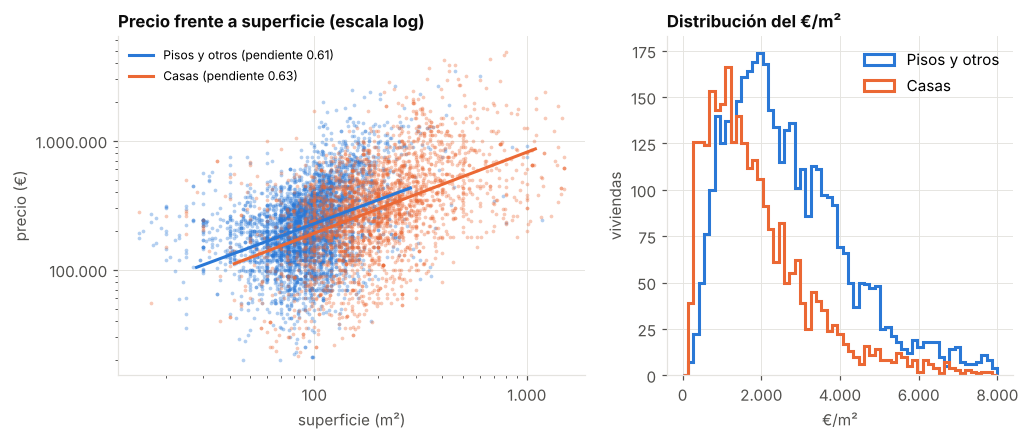

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(10.5, 4), gridspec_kw=dict(width_ratios=[1.35, 1]))
for g, color in GRUPOS.items():
    s = df[df["grupo"] == g]
    lx = np.log(s["superficie_m2"]); ly = np.log(s["precio_eur"])
    b, a = np.polyfit(lx, ly, 1)
    ax[0].scatter(s["superficie_m2"], s["precio_eur"], s=6, alpha=0.35, color=color, linewidth=0)
    xs = np.linspace(lx.quantile(0.01), lx.quantile(0.99), 50)
    ax[0].plot(np.exp(xs), np.exp(a + b * xs), color=color, linewidth=2, label=f"{g} (pendiente {b:.2f})")
ax[0].set(xscale="log", yscale="log", title="Precio frente a superficie (escala log)",
          xlabel="superficie (m²)", ylabel="precio (€)")
ax[0].xaxis.set_major_formatter(miles); ax[0].yaxis.set_major_formatter(miles)
ax[0].legend(loc="upper left", fontsize=8)

bins = np.linspace(0, 8000, 60)
for g, color in GRUPOS.items():
    ax[1].hist(df.loc[df["grupo"] == g, "precio_m2"], bins=bins, color=color, histtype="step",
               linewidth=2, label=g)
ax[1].set(title="Distribución del €/m²", xlabel="€/m²", ylabel="viviendas")
ax[1].xaxis.set_major_formatter(miles)
ax[1].legend()
guardar(fig, "05_pisos_vs_casas")

**Lectura.** Las casas son más grandes (182 m² de mediana frente a 95 m²) y tienen un €/m² menor
(1.565 € frente a 2.414 €). Sin embargo, la relación entre precio y superficie tiene prácticamente
la misma pendiente en ambos grupos (elasticidad de 0,61 en pisos y 0,63 en casas): las dos rectas son casi paralelas y
la diferencia es de **nivel**, es decir, a igual superficie una casa cuesta menos. Además, los dos
grupos se solapan ampliamente. Esto apoya entrenar un único modelo con `tipo_vivienda` como
variable, que basta para recoger un desplazamiento de nivel, como confirmó el tutor; la
explicabilidad (SHAP) permitirá comprobarlo.

## 5. Variables numéricas

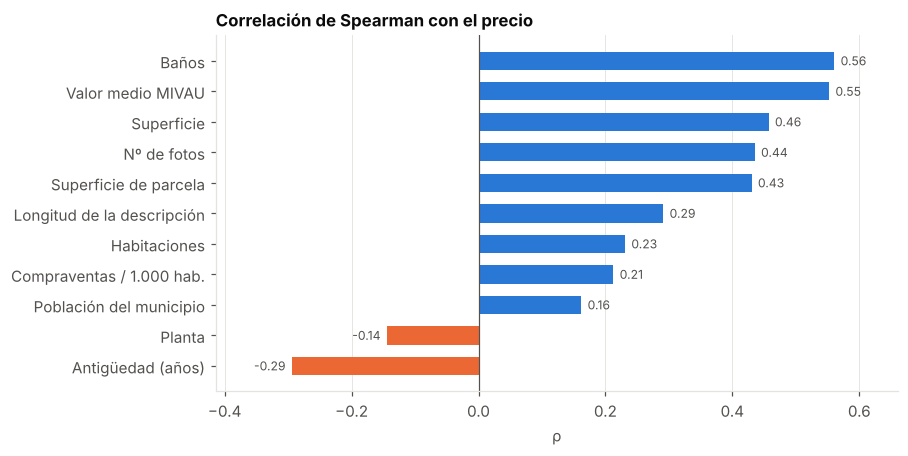

,n,rho_precio,rho_eur_m2
variable,,,
Antigüedad (años),3865,-0.294,-0.259
Planta,1442,-0.144,0.170
Población del municipio,6763,0.162,0.267
Compraventas / 1.000 hab.,6763,0.212,0.259
Habitaciones,6627,0.231,-0.306
Longitud de la descripción,6763,0.291,0.198
Superficie de parcela,1455,0.430,0.133
Nº de fotos,6759,0.435,0.102
Superficie,6763,0.457,-0.327


In [10]:
numericas = {
    "superficie_m2": "Superficie", "habitaciones": "Habitaciones", "banos": "Baños",
    "planta_num": "Planta", "superficie_terreno_m2": "Superficie de parcela",
    "antiguedad_anos": "Antigüedad (años)", "num_fotos": "Nº de fotos",
    "longitud_descripcion": "Longitud de la descripción", "poblacion_2025": "Población del municipio",
    "mivau_trans_por_1000hab": "Compraventas / 1.000 hab.", "mivau_valor_medio_ref_eur": "Valor medio MIVAU",
}
filas = []
for col, nombre in numericas.items():
    s = df[[col, "log_precio", "precio_m2"]].dropna()
    filas.append(dict(variable=nombre, n=len(s),
                      rho_precio=stats.spearmanr(s[col], s["log_precio"]).statistic,
                      rho_eur_m2=stats.spearmanr(s[col], s["precio_m2"]).statistic))
corr = pd.DataFrame(filas).set_index("variable").sort_values("rho_precio")

fig, ax = plt.subplots(figsize=(8, 4.2))
y = np.arange(len(corr))
ax.barh(y, corr["rho_precio"], color=[AZUL if v >= 0 else NARANJA for v in corr["rho_precio"]], height=0.6)
for yi, v in zip(y, corr["rho_precio"]):
    ax.text(v + (0.01 if v >= 0 else -0.01), yi, f"{v:.2f}", va="center",
            ha="left" if v >= 0 else "right", fontsize=8, color=TINTA_2)
ax.axvline(0, color=TINTA_2, linewidth=0.8)
ax.set_yticks(y, corr.index); ax.grid(axis="y", visible=False)
ax.set_xlim(corr["rho_precio"].min() - 0.12, corr["rho_precio"].max() + 0.1)
ax.set(title="Correlación de Spearman con el precio", xlabel="ρ")
guardar(fig, "06_correlaciones_numericas")
corr.round(3)

**Lectura.** Las variables más asociadas al precio son el número de baños (ρ = 0,56), el valor medio
de compraventa del MIVAU (0,55) y la superficie (0,46). El valor del MIVAU es provincial, así que
funciona como un indicador del nivel de precios de la provincia, y es la variable más asociada al
**precio por m²** (0,64), junto con la población y la actividad del mercado: aportan información de
localización complementaria al tamaño. Las habitaciones apenas se asocian al precio (0,23) y lo hacen
negativamente con el €/m² (−0,31): a igual precio, más habitaciones suele indicar viviendas más
grandes en zonas baratas. Destaca el **número de fotos** (0,44), probablemente porque las viviendas
de gama alta se anuncian con más cuidado; es una variable del anuncio, no de la vivienda, y conviene
valorar en el modelado si incluirla. Superficie, habitaciones y baños están muy correlacionadas entre
sí (0,53–0,67), algo a tener en cuenta en la regresión lineal de referencia.

In [11]:
cols = ["superficie_m2", "habitaciones", "banos", "antiguedad_anos", "mivau_trans_por_1000hab", "poblacion_2025"]
df[cols].corr(method="spearman").round(2)

,superficie_m2,habitaciones,banos,antiguedad_anos,mivau_trans_por_1000hab,poblacion_2025
superficie_m2,1.00,0.67,0.66,-0.07,-0.01,-0.14
habitaciones,0.67,1.00,0.53,0.16,-0.15,-0.01
banos,0.66,0.53,1.00,-0.26,0.10,-0.09
antiguedad_anos,-0.07,0.16,-0.26,1.00,-0.19,0.18
mivau_trans_por_1000hab,-0.01,-0.15,0.10,-0.19,1.00,-0.20
poblacion_2025,-0.14,-0.01,-0.09,0.18,-0.20,1.00


## 6. Estado y antigüedad

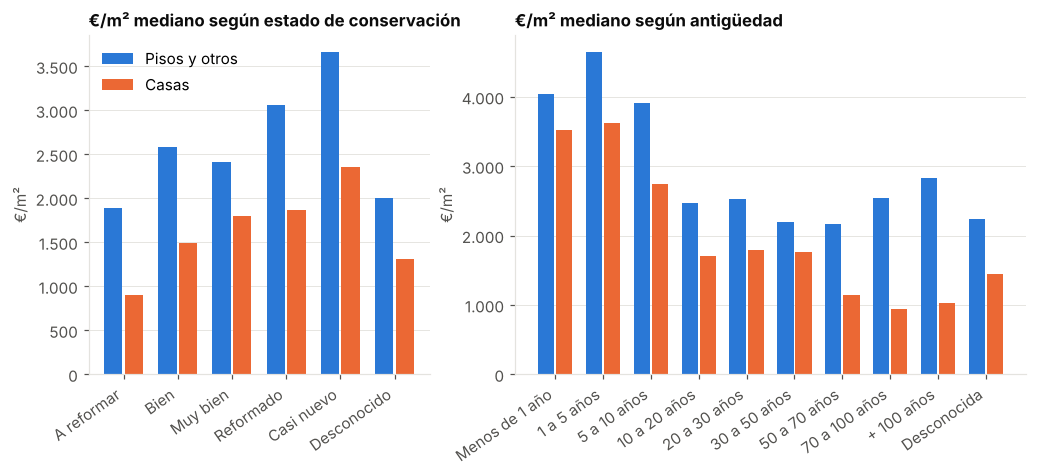

median                size              
grupo          Casas Pisos y otros Casas Pisos y otros
estado                                                
A reformar    900.00       1884.21   294           275
Bien         1496.28       2583.17   398           647
Muy bien     1800.00       2417.61   909          1215
Reformado    1871.78       3058.38   118           226
Casi nuevo   2356.62       3666.67   192           403
Desconocido  1313.56       2002.42   805          1281

In [12]:
ESTADOS = ["A reformar", "Bien", "Muy bien", "Reformado", "Casi nuevo", "Desconocido"]
ANTIG = ["Menos de 1 año", "1 a 5 años", "5 a 10 años", "10 a 20 años", "20 a 30 años",
         "30 a 50 años", "50 a 70 años", "70 a 100 años", "+ 100 años", "Desconocida"]

def mediana_por(col, orden):
    t = df.groupby([col, "grupo"])["precio_m2"].agg(["median", "size"]).unstack("grupo")
    return t.reindex(orden)

fig, ax = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw=dict(width_ratios=[1, 1.5]))
for a, (col, orden, titulo) in zip(ax, [("estado", ESTADOS, "Estado de conservación"),
                                         ("antiguedad", ANTIG, "Antigüedad")]):
    t = mediana_por(col, orden)
    x = np.arange(len(orden)); w = 0.38
    for k, (g, color) in enumerate(GRUPOS.items()):
        a.bar(x + (k - 0.5) * w, t[("median", g)], width=w - 0.04, color=color, label=g)
    a.set_xticks(x, orden, rotation=35, ha="right")
    a.set(title=f"€/m² mediano según {titulo.lower()}", ylabel="€/m²")
    a.yaxis.set_major_formatter(miles); a.grid(axis="x", visible=False)
ax[0].legend()
guardar(fig, "07_estado_antiguedad")
mediana_por("estado", ESTADOS)

**Lectura.** El €/m² crece con el estado de conservación, con la salvedad de que en pisos "Bien"
y "Muy bien" apenas se distinguen (son etiquetas que pone el anunciante). Con la antigüedad
disminuye hasta los 50–70 años y vuelve a subir en los pisos de más de 70 años, que se concentran en
los cascos históricos de las capitales; en las casas, en cambio, la caída es continua. Esta relación
no lineal favorece a los modelos de árboles frente a la regresión lineal. La categoría "Desconocido"
se sitúa en valores intermedios, por lo que mantenerla como categoría propia (en lugar de eliminar
esas viviendas) conserva el tamaño muestral sin introducir un sesgo evidente.

## 7. Equipamiento

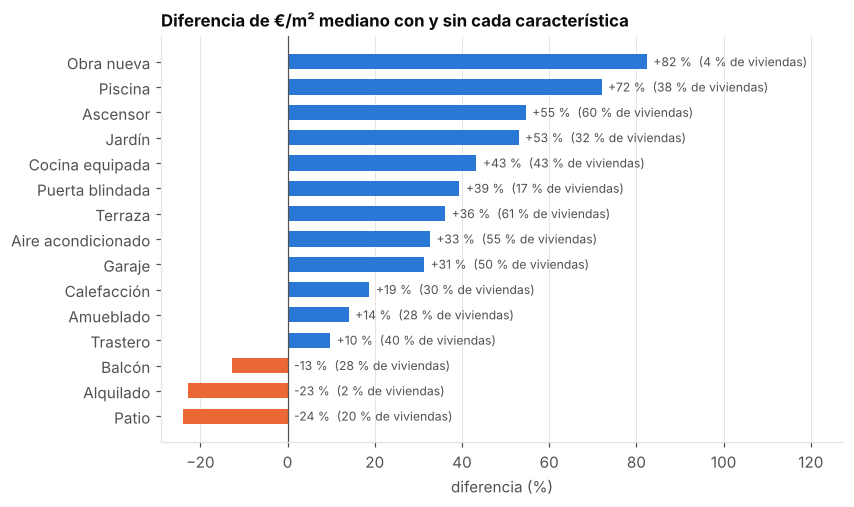

,presentes_pct,dif_pct,p_valor
caracteristica,,,
Patio,20.464,-24.012,0.0
Alquilado,2.499,-22.864,0.0
Balcón,28.168,-12.704,0.0
Trastero,40.012,9.772,0.0
Amueblado,28.286,13.991,0.0
Calefacción,29.602,18.769,0.0
Garaje,49.549,31.313,0.0
Aire acondicionado,55.035,32.633,0.0
Terraza,60.861,36.151,0.0


In [13]:
EQUIP = {"piscina": "Piscina", "ascensor": "Ascensor", "terraza": "Terraza", "parking": "Garaje",
         "jardin": "Jardín", "aire_acondicionado": "Aire acondicionado", "trastero": "Trastero",
         "calefaccion": "Calefacción", "balcon": "Balcón", "cocina_equipada": "Cocina equipada",
         "patio": "Patio", "puerta_blindada": "Puerta blindada", "amueblado": "Amueblado",
         "obra_nueva": "Obra nueva", "alquilado": "Alquilado"}
filas = []
for col, nombre in EQUIP.items():
    con, sin = df.loc[df[col], "precio_m2"], df.loc[~df[col], "precio_m2"]
    filas.append(dict(caracteristica=nombre, presentes_pct=df[col].mean() * 100,
                      dif_pct=(con.median() / sin.median() - 1) * 100,
                      p_valor=stats.mannwhitneyu(con, sin).pvalue))
eq = pd.DataFrame(filas).set_index("caracteristica").sort_values("dif_pct")

fig, ax = plt.subplots(figsize=(8, 4.8))
y = np.arange(len(eq))
ax.barh(y, eq["dif_pct"], color=[AZUL if v >= 0 else NARANJA for v in eq["dif_pct"]], height=0.6)
for yi, (v, p) in enumerate(zip(eq["dif_pct"], eq["presentes_pct"])):
    # Etiqueta siempre a la derecha del cero para no invadir los nombres del eje
    ax.text(max(v, 0) + 1.5, yi, f"{v:+.0f} %  ({p:.0f} % de viviendas)", va="center",
            ha="left", fontsize=8, color=TINTA_2)
ax.axvline(0, color=TINTA_2, linewidth=0.8)
ax.set_yticks(y, eq.index); ax.grid(axis="y", visible=False)
ax.set_xlim(eq["dif_pct"].min() - 5, eq["dif_pct"].max() + 45)
ax.set(title="Diferencia de €/m² mediano con y sin cada característica", xlabel="diferencia (%)")
guardar(fig, "08_equipamiento")
eq.round(3)

**Lectura.** Obra nueva, piscina, ascensor y jardín son las características asociadas a un mayor
€/m². Son diferencias brutas, no efectos causales: una característica puede asociarse a un precio
mayor o menor por las zonas o tipos de vivienda en que es frecuente. Por ejemplo, la piscina abunda
en la costa, y el patio y el balcón, con diferencias negativas, son más habituales en viviendas
antiguas de municipios del interior. Por eso no conviene interpretar estas cifras aisladas; el modelo
y SHAP permitirán separar la contribución de cada característica del resto de variables.

## 8. Contexto de mercado (MIVAU e INE)

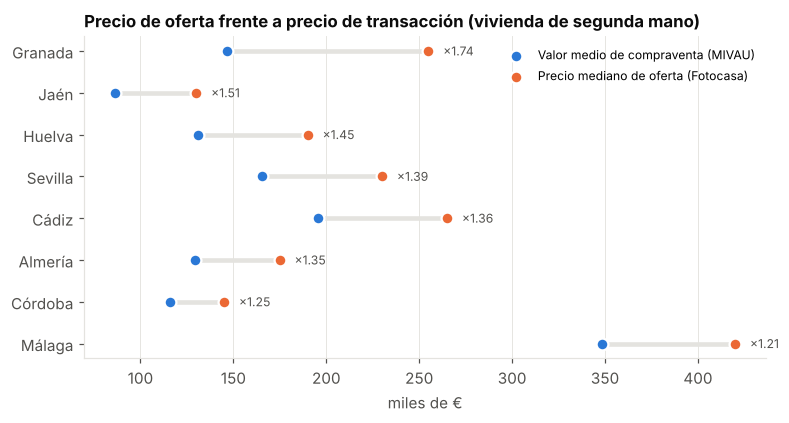

,oferta,mivau,ratio
provincia,,,
Málaga,420000.0,348224.0,1.21
Córdoba,145000.0,116100.0,1.25
Almería,174900.0,129275.0,1.35
Cádiz,265000.0,195302.0,1.36
Sevilla,230000.0,165558.0,1.39
Huelva,190000.0,130862.0,1.45
Jaén,130000.0,86353.0,1.51
Granada,254900.0,146705.0,1.74


In [14]:
prov = df[df["mivau_ref_tipo"] == "segunda_mano"].groupby("provincia").agg(
    oferta=("precio_eur", "median"), mivau=("mivau_valor_medio_ref_eur", "first"))
prov["ratio"] = prov["oferta"] / prov["mivau"]
prov = prov.sort_values("ratio")

fig, ax = plt.subplots(figsize=(8, 3.8))
y = np.arange(len(prov))
ax.hlines(y, prov["mivau"] / 1000, prov["oferta"] / 1000, color=REJILLA, linewidth=3, zorder=1)
ax.scatter(prov["mivau"] / 1000, y, s=60, color=AZUL, edgecolor="white", linewidth=1.5, zorder=2,
           label="Valor medio de compraventa (MIVAU)")
ax.scatter(prov["oferta"] / 1000, y, s=60, color=NARANJA, edgecolor="white", linewidth=1.5, zorder=2,
           label="Precio mediano de oferta (Fotocasa)")
for yi, (o, r) in enumerate(zip(prov["oferta"], prov["ratio"])):
    ax.text(o / 1000 + 8, yi, f"×{r:.2f}", va="center", fontsize=8, color=TINTA_2)
ax.set_yticks(y, prov.index); ax.grid(axis="y", visible=False)
ax.set(title="Precio de oferta frente a precio de transacción (vivienda de segunda mano)", xlabel="miles de €")
ax.legend(loc="upper right", fontsize=8)
guardar(fig, "09_oferta_vs_transaccion")
prov.round(2)

**Lectura.** El precio de oferta supera al de transacción en todas las provincias. La diferencia no
se debe solo al margen de negociación: la muestra de Fotocasa se concentra en los municipios con más
oferta (capitales y costa), mientras que el MIVAU incluye todas las compraventas, también las de
municipios pequeños y más baratos. Es una limitación a señalar: el modelo predice **precio de oferta**,
no precio de cierre.

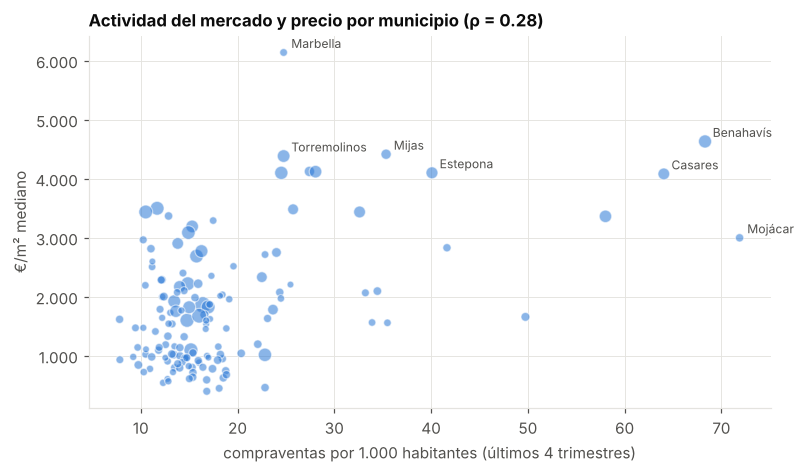

140 municipios con al menos 10 viviendas; tamaño del punto = nº de viviendas


In [15]:
mun = df.groupby(["provincia", "municipio_ine"]).agg(
    viviendas=("precio_m2", "size"), eur_m2=("precio_m2", "median"),
    actividad=("mivau_trans_por_1000hab", "first"), poblacion=("poblacion_2025", "first")).reset_index()
mun = mun[mun["viviendas"] >= 10]

fig, ax = plt.subplots(figsize=(8, 4.4))
ax.scatter(mun["actividad"], mun["eur_m2"], s=np.sqrt(mun["viviendas"]) * 6, color=AZUL, alpha=0.55,
           edgecolor="white", linewidth=0.8)
etiquetados = []
candidatos = pd.concat([mun.nlargest(7, "eur_m2"), mun.nlargest(3, "actividad")]).drop_duplicates("municipio_ine")
for _, r in candidatos.iterrows():
    # Se omite la etiqueta si otra ya ocupa ese hueco
    if any(abs(r["actividad"] - x) < 5 and abs(r["eur_m2"] - y) < 300 for x, y in etiquetados):
        continue
    etiquetados.append((r["actividad"], r["eur_m2"]))
    ax.annotate(r["municipio_ine"], (r["actividad"], r["eur_m2"]), xytext=(5, 3),
                textcoords="offset points", fontsize=8, color=TINTA_2)
rho = stats.spearmanr(mun["actividad"], mun["eur_m2"]).statistic
ax.set(title=f"Actividad del mercado y precio por municipio (ρ = {rho:.2f})",
       xlabel="compraventas por 1.000 habitantes (últimos 4 trimestres)", ylabel="€/m² mediano")
ax.yaxis.set_major_formatter(miles)
guardar(fig, "10_actividad_mercado")
print(f"{len(mun)} municipios con al menos 10 viviendas; tamaño del punto = nº de viviendas")

**Lectura.** Los municipios con más compraventas por habitante (mercados turísticos y de segunda
residencia) son también los más caros por m². La variable resume bien el atractivo del mercado
local y es candidata a ser relevante en el modelo.

## 9. Valores ausentes

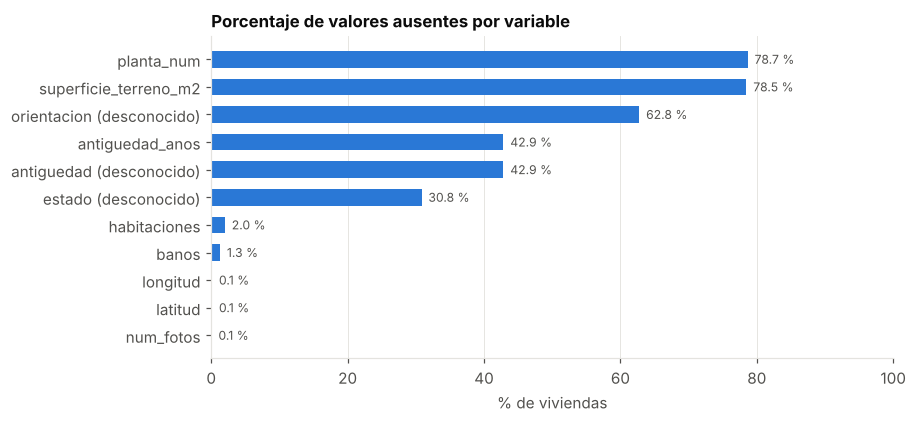

,% ausente
num_fotos,0.1
latitud,0.1
longitud,0.1
banos,1.3
habitaciones,2.0
estado (desconocido),30.8
antiguedad (desconocido),42.9
antiguedad_anos,42.9
orientacion (desconocido),62.8
superficie_terreno_m2,78.5


In [16]:
excluir = {"precio_m2", "bajada_precio_eur", "descripcion", "grupo"}
nulos = (df.drop(columns=list(excluir & set(df.columns))).isna().mean() * 100)
nulos = nulos[nulos > 0].sort_values()
# Categóricas con la categoría "Desconocido/a" también son ausencias encubiertas
for col in ["estado", "antiguedad", "orientacion"]:
    nulos[f"{col} (desconocido)"] = df[col].str.startswith("Desconocid").mean() * 100
nulos = nulos.sort_values()

fig, ax = plt.subplots(figsize=(8, 3.8))
y = np.arange(len(nulos))
ax.barh(y, nulos, color=AZUL, height=0.6)
for yi, v in zip(y, nulos):
    ax.text(v + 1, yi, f"{v:.1f} %", va="center", fontsize=8, color=TINTA_2)
ax.set_yticks(y, nulos.index); ax.grid(axis="y", visible=False)
ax.set_xlim(0, 100)
ax.set(title="Porcentaje de valores ausentes por variable", xlabel="% de viviendas")
guardar(fig, "11_valores_ausentes")
nulos.round(1).to_frame("% ausente")

In [17]:
# Planta: ausente sobre todo en casas, donde no aplica
pd.crosstab(df["grupo"], df["planta_num"].notna(), normalize="index").round(3).rename(
    columns={True: "con planta", False: "sin planta"})

planta_num,sin planta,con planta
grupo,,
Casas,0.914,0.086
Pisos y otros,0.702,0.298


## 10. Conclusiones para el preprocesado y el modelado

1. **Variable objetivo**: se modelará `log_precio`; las métricas se expresarán en euros tras
   deshacer la transformación.
2. **Territorio**: la provincia es insuficiente; se usarán el municipio (vía variables INE/MIVAU),
   el indicador de capital y las coordenadas.
3. **Pisos y casas**: comportamiento distinto pero solapado. Propuesta: un único modelo con
   `tipo_vivienda`, a confirmar con el tutor.
4. **Ausentes**: los modelos de árboles (XGBoost, LightGBM, CatBoost) admiten ausentes de forma nativa;
   para la regresión lineal y Random Forest se imputarán (mediana y categoría "Desconocido") con
   indicador de ausencia. La planta solo es informativa en pisos.
5. **Multicolinealidad**: superficie, habitaciones y baños están muy correlacionadas; no afecta a los
   árboles, pero sí a la interpretación de la regresión lineal.
6. **Variables excluidas como predictoras**: `precio_m2` y `bajada_precio_eur` (derivan del precio)
   e identificadores (`id_anuncio`, `enlace`).
7. **Validación**: dada la heterogeneidad territorial, la partición entrenamiento/prueba se
   estratificará por provincia.